Dataset loaded.
Original data shape: (5847, 14), Cleaned data shape: (814, 14)

Data preparation complete. X_final shape: (814, 337), y_final shape: (814, 1)

Starting training with learning rate=0.01, iterations=1000


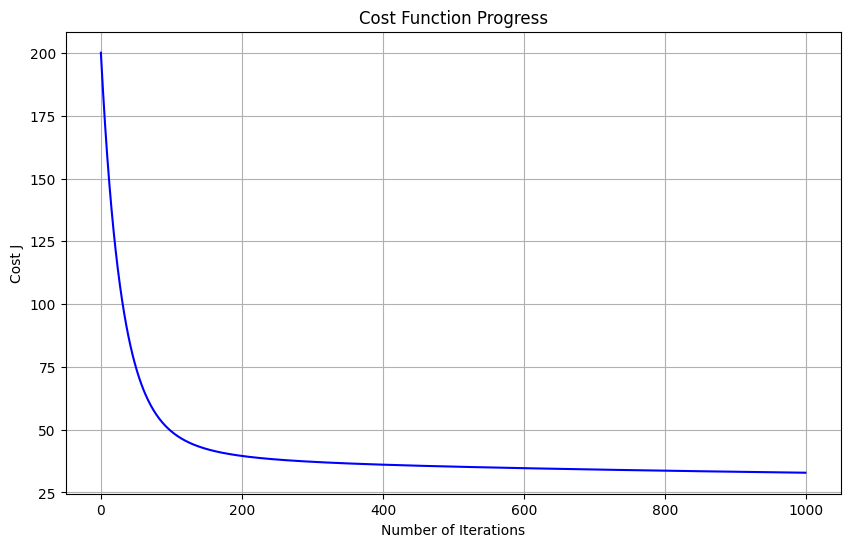


Final Coefficients (theta):
[[ 1.25706575e+01]
 [ 2.91072346e+00]
 [-1.25106975e+00]
 [ 2.82310730e-01]
 [ 4.75156374e+00]
 [ 7.63988137e+00]
 [-1.83849619e+00]
 [ 8.79782801e-02]
 [-6.97684344e-02]
 [ 2.08055912e-01]
 [ 3.93896941e-01]
 [ 2.20592142e-01]
 [ 2.02454947e-01]
 [ 1.20472006e-01]
 [ 3.93193827e-01]
 [ 1.08020074e+00]
 [-6.28597206e-01]
 [-8.34562367e-01]
 [-3.79767939e-01]
 [ 7.91246142e-01]
 [ 5.10673078e-02]
 [ 3.82100422e-01]
 [-2.34567673e-01]
 [-1.21813829e-01]
 [ 1.72495988e-02]
 [ 1.05043978e-01]
 [ 1.43916450e-01]
 [ 5.33155252e-02]
 [ 4.08398037e-01]
 [ 8.15826578e-02]
 [ 4.49882371e-02]
 [ 5.91339377e-02]
 [ 5.56061441e-02]
 [ 1.42228795e-01]
 [ 4.86173967e-02]
 [-6.88592403e-02]
 [-8.44185565e-02]
 [-2.74728902e-03]
 [-1.22312676e-01]
 [-3.54898888e-02]
 [-2.72175249e-02]
 [-1.63940249e-01]
 [-1.41563389e-01]
 [-7.59097112e-02]
 [-4.27053340e-02]
 [ 3.61956502e-02]
 [-3.92677335e-02]
 [ 8.76689445e-02]
 [-4.60076812e-02]
 [-3.06975590e-01]
 [-7.88774803e-02]
 [

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# --- Data Loading and Basic Preprocessing for Multiple Regression ---

# NOTE: Please download the 'car_prices.csv' dataset from the provided Kaggle link:
# https://www.kaggle.com/datasets/sujay1844/used-car-prices
# and place it in the same directory as this notebook.

# A student might just assume the file is there or handle errors less gracefully.
data = pd.read_csv("/content/train2.csv")
print("Dataset loaded.")

# Data Cleaning: Drop rows with any missing values.
# A student might start with a simple dropna.
clean_data = data.dropna()
print(f"Original data shape: {data.shape}, Cleaned data shape: {clean_data.shape}")


# SPLITTING DATA INTO INPUT AND OUTPUT FEATURES
# Let's select some features a student might pick for a first attempt.
# For simplicity, we'll manually define numerical and categorical features.

# Define numerical and categorical features based on the actual column names from clean_data.columns
numerical_cols = ['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats']
categorical_cols = ['Name', 'Location', 'Fuel_Type', 'Transmission', 'Owner_Type']
target_col = 'Price'

# Create feature matrix (X) and target vector (y)
X_raw = clean_data[numerical_cols + categorical_cols]
y_raw = clean_data[target_col].values.reshape(-1, 1)


# Manual Feature Scaling for Numerical Features (Standardization)
# A student might implement this step-by-step.
X_numerical = clean_data[numerical_cols].copy()

# --- Specific cleaning for 'Mileage' column ---
# This column contains strings with units, need to convert to numeric
X_numerical['Mileage'] = X_numerical['Mileage'].astype(str).str.replace(' km/kg', '', regex=False)
X_numerical['Mileage'] = X_numerical['Mileage'].astype(str).str.replace(' kmpl', '', regex=False)
X_numerical['Mileage'] = pd.to_numeric(X_numerical['Mileage'], errors='coerce')
# Fill any NaNs created by 'coerce' or existing NaNs with the median
# A student might use mean, but median is more robust to outliers
mileage_median = X_numerical['Mileage'].median()
X_numerical['Mileage'] = X_numerical['Mileage'].fillna(mileage_median)

# --- Specific cleaning for 'Engine' column ---
# This column also contains strings with units (CC), need to convert to numeric
X_numerical['Engine'] = X_numerical['Engine'].astype(str).str.replace(' CC', '', regex=False)
X_numerical['Engine'] = pd.to_numeric(X_numerical['Engine'], errors='coerce')
engine_median = X_numerical['Engine'].median()
X_numerical['Engine'] = X_numerical['Engine'].fillna(engine_median)

# --- Specific cleaning for 'Power' column ---
# This column also contains strings with units (bhp), need to convert to numeric
X_numerical['Power'] = X_numerical['Power'].astype(str).str.replace(' bhp', '', regex=False)
X_numerical['Power'] = pd.to_numeric(X_numerical['Power'], errors='coerce')
power_median = X_numerical['Power'].median()
X_numerical['Power'] = X_numerical['Power'].fillna(power_median)


for col in numerical_cols:
    mean_val = X_numerical[col].mean()
    std_val = X_numerical[col].std()
    # Handle cases where std_val might be 0 to avoid division by zero
    if std_val != 0:
        X_numerical[col] = (X_numerical[col] - mean_val) / std_val
    else:
        X_numerical[col] = 0 # If std is 0, all values are the same, so scaled to 0

# Manual One-Hot Encoding for Categorical Features
# Using pandas get_dummies is a common way for students to do this before sklearn
X_categorical = pd.get_dummies(clean_data[categorical_cols], drop_first=True) # drop_first to avoid dummy variable trap

# Combine preprocessed numerical and categorical features
# Convert to numpy arrays for consistency with gradient descent functions
X_processed = np.hstack((X_numerical.values, X_categorical.values))

# Add an intercept term (bias) to the feature matrix X
# This is a standard step for linear regression
X_final = np.c_[np.ones(X_processed.shape[0]), X_processed]

# Ensure y is a column vector
y_final = y_raw

print(f"\nData preparation complete. X_final shape: {X_final.shape}, y_final shape: {y_final.shape}")


# ML MODELLING - Multiple Variable Linear Regression

# define hypothesis function for multiple variables
def hypothesis(X, theta):
  # Predicted output using matrix multiplication
  return X @ theta

# defining cost function (Mean Squared Error)
def cost_function(X, y, theta, m):
  predictions = hypothesis(X, theta)
  error = predictions - y
  return (1/(2*m)) * np.sum(error**2)

# defining the gradient descent
def gradient_descent(X, y, theta, m, alpha):
  predictions = hypothesis(X, theta)
  error = predictions - y
  # Gradient calculation for all features
  gradients = (1/m) * (X.T @ error)
  theta_new = theta - alpha * gradients
  return theta_new

# training the model
def training(X, y, alpha, iters):
  m, n = X.shape # m = samples, n = features (including intercept)
  theta = np.zeros((n, 1)) # Initialize theta with zeros
  cost_history = []

  for i in range(iters):
    theta = gradient_descent(X, y, theta, m, alpha)
    cost = cost_function(X, y, theta, m)
    cost_history.append(cost)

  # Plotting the cost history to see convergence
  plt.figure(figsize=(10, 6))
  plt.plot(np.arange(len(cost_history)), cost_history, 'b-')
  plt.title('Cost Function Progress')
  plt.xlabel('Number of Iterations')
  plt.ylabel('Cost J')
  plt.grid(True)
  plt.show()

  return theta, cost_history


# Prepare data for training
x_train = X_final
y_train = y_final

alpha = 0.01 # Learning rate
iter = 1000 # Number of iterations.

print(f"\nStarting training with learning rate={alpha}, iterations={iter}")

# Train the model
final_theta, cost_values = training(x_train, y_train, alpha, iter)

print("\nFinal Coefficients (theta):")
print(final_theta)

print(f"\nFinal Cost: {cost_values[-1]:.4f}")

# Simple example of making a prediction using the trained model
# This part might be commented out or kept very basic by a student.
# A student might not immediately implement a full prediction pipeline.
# print("\nExample prediction (requires manual new data preprocessing): Not implemented in this basic example.")

In [2]:
print(clean_data.columns)

Index(['Unnamed: 0', 'Name', 'Location', 'Year', 'Kilometers_Driven',
       'Fuel_Type', 'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power',
       'Seats', 'New_Price', 'Price'],
      dtype='object')
